In [1]:
import adabmDCA as dca
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import RNA

from ptt.io import load_sampler_from_filename
from rbms.utils import get_flagged_updates, get_saved_updates
from ptt.utils import get_sampler
from adabmDCA import import_from_fasta
from ptt import retrieve_ll

from concurrent.futures import ProcessPoolExecutor
from functools import partial

# use latex and font size 14
plt.rc('text', usetex=True)
plt.rc('font', size=14)

tokens = "ACGU-"
dot_bracket_with_pk = "...(((((((..((....)).)))))))...((((((....((((((...((...((((((....))))))..))...))))))(((...(.((((((....)))))).)..)))...[.[[[[[...))))))((((...(((....)))..))))......]]]]]]..((.(((((....))))).....)).."

/home/lorenzo/Documents/rbms/rbms/dataset/dataset_class.py:8: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

In [3]:
def compute_bpp_matrix(sequence):
    """
    Compute the base-pairing probability (bpp) matrix via ViennaRNA.

    Parameters
    ----------
    sequence : str
        RNA sequence (T già convertiti in U se presenti gap).

    Returns
    -------
    bpp : np.ndarray, shape (L, L)
        Matrice simmetrica delle probabilità di appaiamento (L = len(sequence)).
    """
    fc = RNA.fold_compound(sequence)
    propensity, ensemble_energy = fc.pf()
    basepair_probs = fc.bpp()  # nested list, 1-based

    L = len(sequence)
    bpp = np.zeros((L, L), dtype=float)
    for i in range(1, L+1):
        for j in range(1, L+1):
            bpp[i-1, j-1] = basepair_probs[i][j]
    return bpp


def dot_bracket_to_ss_matrix(ss):
    """
    Convert a dot-bracket string into a binary contact matrix.

    Parameters
    ----------
    ss : str
        Notazione secondaria “dot-bracket”.

    Returns
    -------
    cm : np.ndarray, shape (L, L)
        Matrice binaria con cm[i,j]=1 se i e j sono appaiati nella struttura.
    """
    L = len(ss)
    cm = np.zeros((L, L), dtype=int)
    stack_round = []  # for (
    stack_square = []  # for [
    stack_angle = []  # for <
    stack_curly = []  # for {
    for pos, c in enumerate(ss):
        if c == '(':
            stack_round.append(pos)
        elif c == '[':
            stack_square.append(pos)
        elif c == '<':
            stack_angle.append(pos)
        elif c == '{':
            stack_curly.append(pos)
        elif c == ')':
            if stack_round:
                i = stack_round.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == ']':
            if stack_square:
                i = stack_square.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '>':
            if stack_angle:
                i = stack_angle.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '}':
            if stack_curly:
                i = stack_curly.pop()
                cm[i, pos] = cm[pos, i] = 1
    return cm



def _bpp_score_for_sequence(seq, cm):
    seq = seq.upper().replace('T', 'U')
    bpp = compute_bpp_matrix(seq)
    return float((bpp * cm).sum())

def compute_bpp_scores(sequences_one_hot, dot_bracket, num_workers=4):
    sequences_v = torch.argmax(sequences_one_hot, dim=-1)
    sequences = ["GUG"+ "".join(tokens[i] for i in sequence) + "G" for sequence in sequences_v]

    """
    Compute BPP scores and gap violations for a list of sequences given a dot-bracket structure.

    Args:
        sequences (list of str): List of RNA sequences (strings with 'U' instead of 'T').
        dot_bracket (str): Dot-bracket string representing the structure.
        num_workers (int): Number of processes to parallelize over.

    Returns:
        bpp_scores (list of float): BPP scores for each sequence.
        gap_violations (int): Number of gap violations across all sequences.
    """
    # Convert dot-bracket to structure matrix once
    cm = dot_bracket_to_ss_matrix(dot_bracket)

    # Use process pool to parallelize computation
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        bpp_scores = list(executor.map(partial(_bpp_score_for_sequence, cm=cm), sequences))

    return bpp_scores

In [62]:
path_model_franc = "/home/lorenzo/Documents/paths-specificity/Group_I_Intron/modello_FC_T=1"
path_model_lore = "/home/lorenzo/Documents/paths-specificity/lore/per_giova/models/eaDCA_params.dat"
path_model_bmdca = "/home/lorenzo/Documents/paths-specificity/lore/per_giova/models/bmDCA_params.dat"
path_model_rbm = "/home/lorenzo/Documents/paths-specificity/lore/per_giova/models/rbm_ptt_azeo_weighted.h5"
path_azo = "/home/lorenzo/Documents/paths-specificity/Group_I_Intron/azo.seq"
path_data = "/home/lorenzo/Documents/paths-specificity/lore/per_giova/fasta_azeo.fasta"
path_test = "/home/lorenzo/Documents/paths-specificity/lore/per_giova/samples_eaDCA_nogap.fasta"

azo = import_from_fasta(path_azo, tokens=tokens)[1]
azo_enc = torch.tensor(azo, dtype=torch.long, device=device)
azo_oh = torch.nn.functional.one_hot(azo_enc, num_classes=len(tokens)).float()

params_np = np.load(path_model_franc)
params_franc = {
    'bias': torch.tensor(params_np['h_local'], dtype=torch.float32, device='cuda').contiguous(),
    'coupling_matrix': torch.tensor(params_np['couplings'], dtype=torch.float32, device='cuda').contiguous()
}

params_lore = dca.load_params(path_model_lore, tokens=tokens, device=device, dtype=dtype)
# Set the bias of the gaps to a very large negative value to avoid gaps in the sequences
gap_idz = tokens.index('-')
params_lore['bias'][:, gap_idz] = -1e6

params_bmdca = dca.load_params(path_model_bmdca, tokens=tokens, device=device, dtype=dtype)
params_bmdca['bias'][:, gap_idz] = -1e6

saved_updates, train_ll, test_ll, sampler_rbm_orig = retrieve_ll(
    path_model_rbm,
    path_data,
    path_test,
    device=device,
    use_weights=False,
    recompute=True,
    alphabet=tokens,
)

sampler_rbm = sampler_rbm_orig.clone()
for i in range(len(sampler_rbm._vbias)):
    sampler_rbm._vbias[i][:, gap_idz] = -1e6

Reading dataset from /home/lorenzo/Documents/paths-specificity/lore/per_giova/fasta_azeo.fasta...
    Done
Reading dataset from /home/lorenzo/Documents/paths-specificity/lore/per_giova/samples_eaDCA_nogap.fasta...
    Done
Selected updates for PTT: [    1   569   655   781   892  1091  1292  1563  2102  2758  3724  4735
  6192  8285 10739 14652 19476 25789 30000]
No RCM found.


  0%|          | 0/19 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

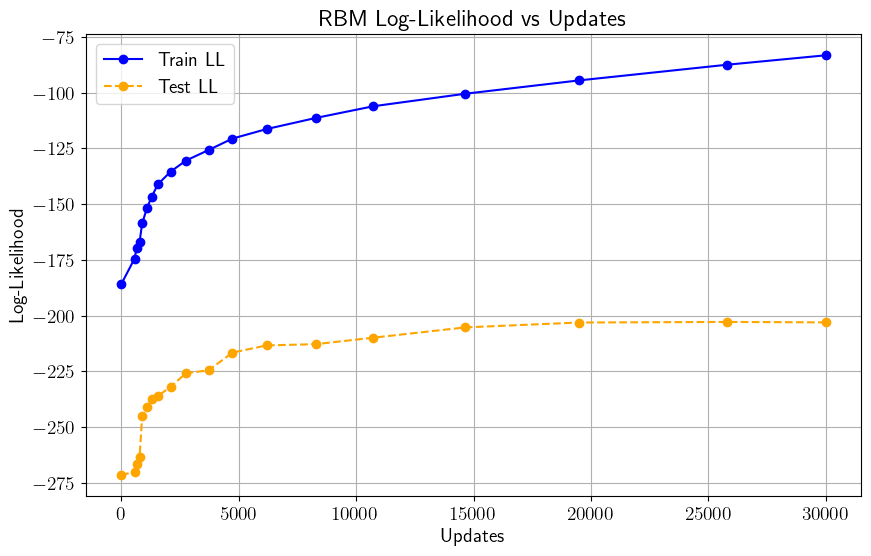

In [63]:
# plot LL vs updates
plt.figure(figsize=(10, 6))
plt.plot(saved_updates, train_ll, "-o", label="Train LL", color="blue")
plt.plot(saved_updates, test_ll, "--o", label="Test LL", color="orange")
plt.xlabel("Updates")
plt.ylabel("Log-Likelihood")
plt.title("RBM Log-Likelihood vs Updates")
plt.legend()
plt.grid()
plt.show()

In [64]:
num_chains = 10000
nsweeps = 1000

L, q = params_franc['bias'].shape
init_chains = dca.utils.init_chains(
    num_chains=num_chains,
    L=L,
    q=q,
    device=device,
    dtype=dtype,
)

In [65]:
print("Sampling with eDCA Franc...")
samples_franc = dca.gibbs_sampling(
    chains=init_chains,
    params=params_franc,
    nsweeps=nsweeps,
)

print("Sampling with eDCA Lore...")
samples_lore = dca.gibbs_sampling(
    chains=init_chains,
    params=params_lore,
    nsweeps=nsweeps,
)

print("Sampling with bmDCA")
samples_bmDCA = dca.gibbs_sampling(
    chains=init_chains,
    params=params_bmdca,
    nsweeps=nsweeps,
)

print("Sampling with RBM...")
sampler_rbm.init_random_chains(num_chains)
sampler_rbm.sample(nsweeps, increment=1, show_pbar=True)
samples_rbm = sampler_rbm._v[-1].reshape(num_chains, L, q)

Sampling with RBM...


  0%|          | 0/1000 [00:00<?, ?it/s]

In [67]:
id_rbm = -1
print(saved_updates[id_rbm])
samples_rbm = sampler_rbm._v[id_rbm].reshape(num_chains, L, q)

30000


In [68]:
# check histogram of distances from azo
from adabmDCA import get_seqid

distances_franc = L - get_seqid(azo_oh, samples_franc)
distances_lore = L - get_seqid(azo_oh, samples_lore)
distances_rbm = L - get_seqid(azo_oh, samples_rbm)
distances_bmdca = L - get_seqid(azo_oh, samples_bmDCA)

df_distances = pd.DataFrame({
    'Distance from Azo Franc': distances_franc.cpu().numpy(),
    'Distance from Azo Lore': distances_lore.cpu().numpy(),
    'Distance from Azo RBM': distances_rbm.cpu().numpy(),
    'Distance from Azo bmDCA': distances_bmdca.cpu().numpy()
})

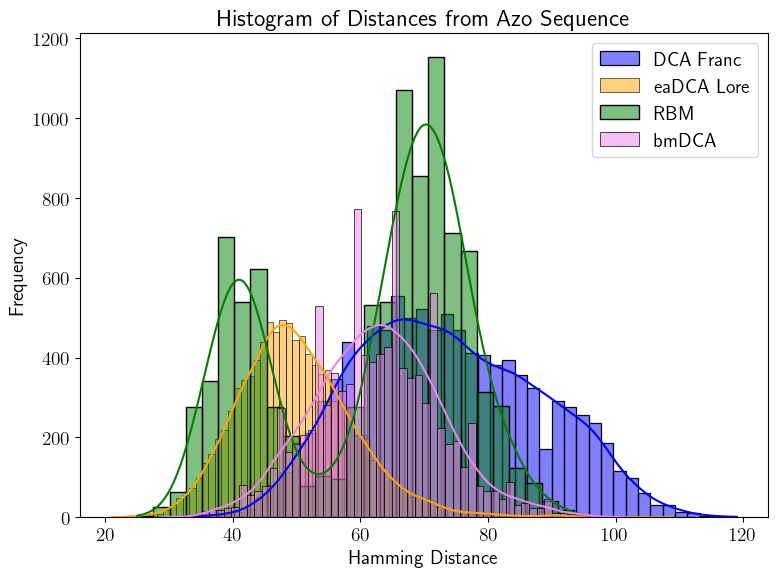

In [69]:
fig = plt.figure(figsize=(8,6))
sns.histplot(
    data=df_distances,
    x='Distance from Azo Franc',
    color='blue',
    kde=True,
    label='DCA Franc'
)
sns.histplot(
    data=df_distances,
    x='Distance from Azo Lore',
    color='orange',
    kde=True,
    label='eaDCA Lore'
)
sns.histplot(
    data=df_distances,
    x='Distance from Azo RBM',
    color='green',
    kde=True,
    label='RBM'
)
sns.histplot(
    data=df_distances,
    x='Distance from Azo bmDCA',
    color='violet',
    kde=True,
    label='bmDCA'
)
plt.legend()
plt.title('Histogram of Distances from Azo Sequence')
plt.xlabel('Hamming Distance')
plt.ylabel('Frequency')
plt.tight_layout()

In [79]:
dmin, dmaz = 60, 80
print(f"Number of sequences within distance {dmin} to {dmaz} to Azo:")
print("DCA Franc:", np.sum((distances_franc.cpu().numpy() >= dmin) & (distances_franc.cpu().numpy() <= dmaz)))
print("eaDCA Lore:", np.sum((distances_lore.cpu().numpy() >= dmin) & (distances_lore.cpu().numpy() <= dmaz)))
print("RBM:", np.sum((distances_rbm.cpu().numpy() >= dmin) & (distances_rbm.cpu().numpy() <= dmaz)))
print("bmDCA:", np.sum((distances_bmdca.cpu().numpy() >= dmin) & (distances_bmdca.cpu().numpy() <= dmaz)))

Number of sequences within distance 60 to 80 to Azo:
DCA Franc: 4996
eaDCA Lore: 1339
RBM: 5959
bmDCA: 5807


In [80]:
# select nsel sequences within the distance range
nsel = 1000
idx_franc = np.where((distances_franc.cpu().numpy() >= dmin) & (distances_franc.cpu().numpy() <= dmaz))[0][:nsel]
idx_lore = np.where((distances_lore.cpu().numpy() >= dmin) & (distances_lore.cpu().numpy() <= dmaz))[0][:nsel]
idx_rbm = np.where((distances_rbm.cpu().numpy() >= dmin) & (distances_rbm.cpu().numpy() <= dmaz))[0][:nsel]
idx_bmdca = np.where((distances_bmdca.cpu().numpy() >= dmin) & (distances_bmdca.cpu().numpy() <= dmaz))[0][:nsel]

In [81]:
bpp_scores_franc = compute_bpp_scores(samples_franc[idx_franc], dot_bracket_with_pk, num_workers=20)
bpp_scores_lore = compute_bpp_scores(samples_lore[idx_lore], dot_bracket_with_pk, num_workers=20)
bpp_scores_rbm = compute_bpp_scores(samples_rbm[idx_rbm], dot_bracket_with_pk, num_workers=20)
bpp_scores_bmdca = compute_bpp_scores(samples_bmDCA[idx_rbm], dot_bracket_with_pk, num_workers=20)

In [82]:
energies_franc_by_lore = dca.compute_energy(samples_lore[idx_lore], params_franc)
energies_lore_by_franc = dca.compute_energy(samples_franc[idx_franc], params_lore)
energies_franc_by_franc = dca.compute_energy(samples_franc[idx_franc], params_franc)
energies_lore_by_lore = dca.compute_energy(samples_lore[idx_lore], params_lore)
energies_rbm_by_franc = dca.compute_energy(samples_rbm[idx_rbm], params_franc)
energies_rbm_by_lore = dca.compute_energy(samples_rbm[idx_rbm], params_lore)
energies_bmdca_by_franc = dca.compute_energy(samples_bmDCA[idx_bmdca], params_franc)
energies_bmdca_by_lore = dca.compute_energy(samples_bmDCA[idx_bmdca], params_lore)

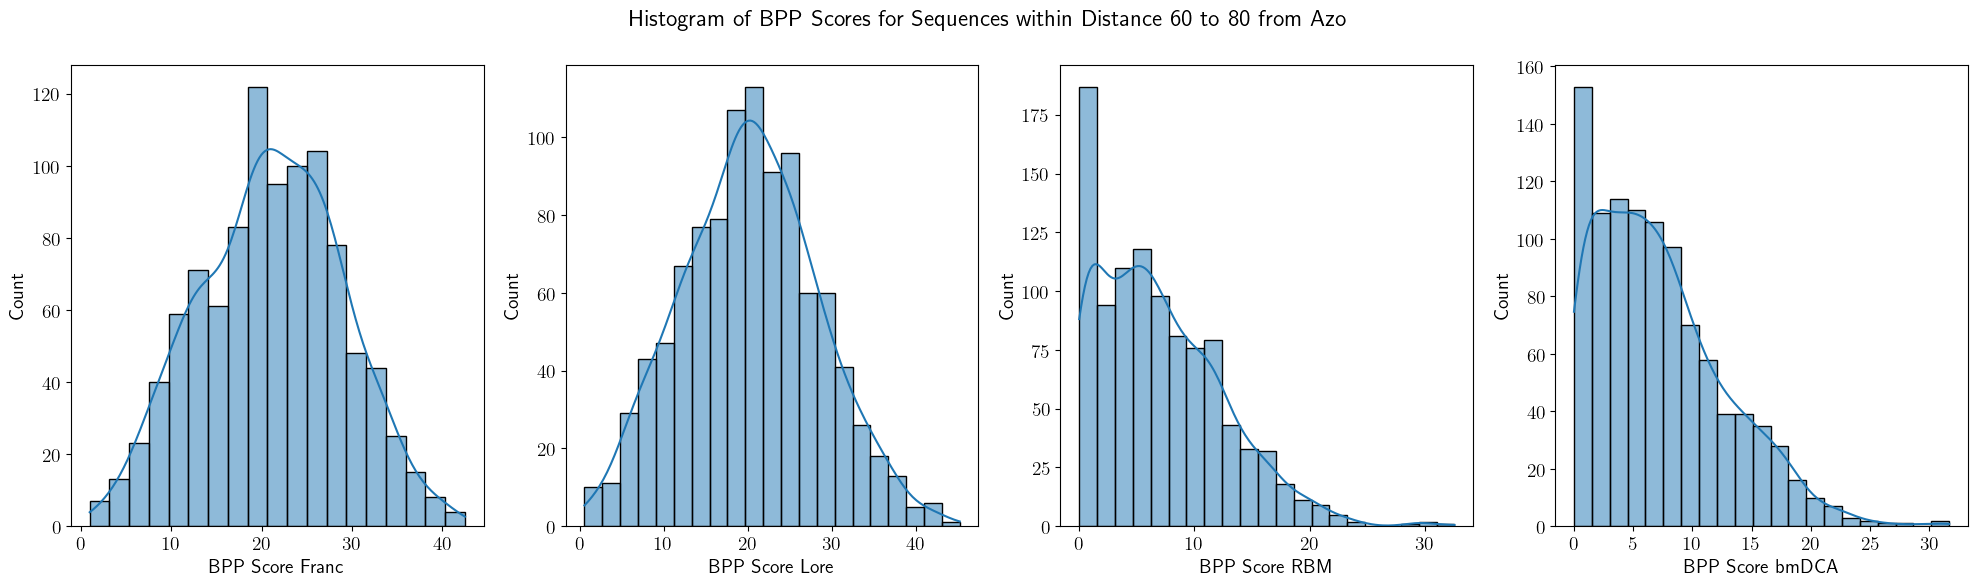

In [83]:
df_results = pd.DataFrame({
    'BPP Score Franc': bpp_scores_franc,
    'BPP Score Lore': bpp_scores_lore,
    'Energy Franc by Lore': energies_franc_by_lore.cpu().numpy(),
    'Energy Lore by Franc': energies_lore_by_franc.cpu().numpy(),
    'Energy Franc by Franc': energies_franc_by_franc.cpu().numpy(),
    'Energy Lore by Lore': energies_lore_by_lore.cpu().numpy(),
    'BPP Score RBM': bpp_scores_rbm,
    'BPP Score bmDCA': bpp_scores_bmdca,
    'Energy RBM by Franc': energies_rbm_by_franc.cpu().numpy(),
    'Energy RBM by Lore': energies_rbm_by_lore.cpu().numpy(),
    'Energy bmDCA by Franc': energies_bmdca_by_franc.cpu().numpy(),
    'Energy bmDCA by Lore': energies_bmdca_by_lore.cpu().numpy(),
})

fig, ax = plt.subplots(1, 4, figsize=(20,6))
sns.histplot(
    data=df_results,
    x='BPP Score Franc',
    ax=ax[0],
    kde=True
)
sns.histplot(
    data=df_results,
    x='BPP Score Lore',
    ax=ax[1],
    kde=True
)

sns.histplot(
    data=df_results,
    x='BPP Score RBM',
    ax=ax[2],
    kde=True
)

sns.histplot(
    data=df_results,
    x='BPP Score bmDCA',
    ax=ax[3],
    kde=True,
)

fig.suptitle(f'Histogram of BPP Scores for Sequences within Distance {dmin} to {dmaz} from Azo')
plt.tight_layout()

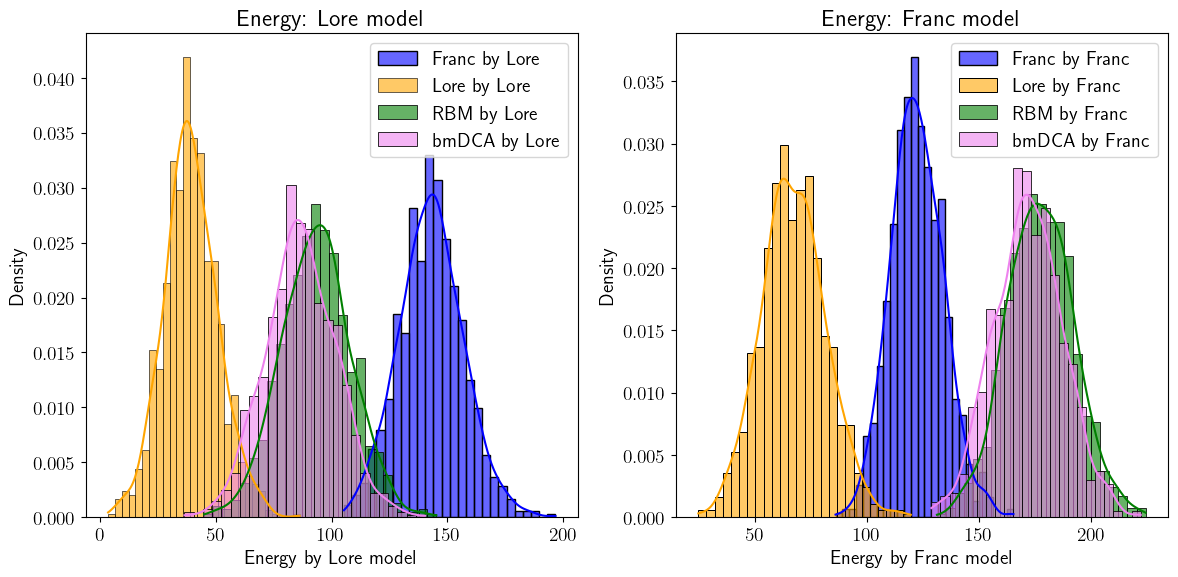

In [84]:
fig, ax = plt.subplots(1, 2, figsize=(12,6))

# Histogram of energies Franc by Lore vs Lore by Lore
sns.histplot(
    data=df_results,
    x='Energy Franc by Lore',
    ax=ax[0],
    color='blue',
    label='Franc by Lore',
    kde=True,
    stat='density',
    alpha=0.6
)
sns.histplot(
    data=df_results,
    x='Energy Lore by Lore',
    ax=ax[0],
    color='orange',
    label='Lore by Lore',
    kde=True,
    stat='density',
    alpha=0.6
)

sns.histplot(
    data=df_results,
    x='Energy RBM by Lore',
    ax=ax[0],
    color='green',
    label='RBM by Lore',
    kde=True,
    stat='density',
    alpha=0.6
)

sns.histplot(
    data=df_results,
    x='Energy bmDCA by Lore',
    ax=ax[0],
    color='violet',
    label='bmDCA by Lore',
    kde=True,
    stat='density',
    alpha=0.6
)
ax[0].legend()
ax[0].set_xlabel('Energy by Lore model')
ax[0].set_title('Energy: Lore model')

sns.histplot(
    data=df_results,
    x='Energy Franc by Franc',
    ax=ax[1],
    color='blue',
    label='Franc by Franc',
    kde=True,
    stat='density',
    alpha=0.6
)

# Histogram of energies Lore by Franc vs Franc by Franc
sns.histplot(
    data=df_results,
    x='Energy Lore by Franc',
    ax=ax[1],
    color='orange',
    label='Lore by Franc',
    kde=True,
    stat='density',
    alpha=0.6
)

sns.histplot(
    data=df_results,
    x='Energy RBM by Franc',
    ax=ax[1],
    color='green',
    label='RBM by Franc',
    kde=True,
    stat='density',
    alpha=0.6
)

sns.histplot(
    data=df_results,
    x='Energy bmDCA by Franc',
    ax=ax[1],
    color='violet',
    label='bmDCA by Franc',
    kde=True,
    stat='density',
    alpha=0.6
)



ax[1].legend()
ax[1].set_title('Energy: Franc model')
ax[1].set_xlabel('Energy by Franc model')
plt.tight_layout()

In [76]:
# For the RBM model, compute the trajectory of average distance from Azo during sampling and average bpp score during training
evaluate_cell = True # Takes a lot of time
if evaluate_cell:
    samples_traj_rbm = sampler_rbm._v.reshape(-1, num_chains, L, q)  # shape (nsweeps, num_chains, L, q)
    avg_distances_rbm = []
    std_distances_rbm = []
    avg_bpp_scores_rbm = []
    std_bpp_scores_rbm = []
    for sweep_idx in range(samples_traj_rbm.shape[0]):
        print(f"Analyzing sweep {sweep_idx+1}/{samples_traj_rbm.shape[0]}...")
        samples_sweep = samples_traj_rbm[sweep_idx]
        distances_sweep = L - get_seqid(azo_oh, samples_sweep)
        avg_distance = distances_sweep.float().mean().item()
        std_distance = distances_sweep.float().std().item()
        avg_distances_rbm.append(avg_distance)
        std_distances_rbm.append(std_distance)

        bpp_scores_sweep = compute_bpp_scores(samples_sweep, dot_bracket_with_pk, num_workers=20)
        avg_bpp_score = np.mean(bpp_scores_sweep)
        std_bpp_score = np.std(bpp_scores_sweep)
        avg_bpp_scores_rbm.append(avg_bpp_score)
        std_bpp_scores_rbm.append(std_bpp_score)
    # save results of the previous cell in a npy file
    np.savez(
        "rbm_azeo_distance_bpp_trajectory_weighted.npz",
        avg_distances_rbm=np.array(avg_distances_rbm),
        std_distances_rbm=np.array(std_distances_rbm),
        avg_bpp_scores_rbm=np.array(avg_bpp_scores_rbm),
        std_bpp_scores_rbm=np.array(std_bpp_scores_rbm),
    )

Analyzing sweep 1/19...
Analyzing sweep 2/19...
Analyzing sweep 2/19...
Analyzing sweep 3/19...
Analyzing sweep 3/19...
Analyzing sweep 4/19...
Analyzing sweep 4/19...
Analyzing sweep 5/19...
Analyzing sweep 5/19...
Analyzing sweep 6/19...
Analyzing sweep 6/19...
Analyzing sweep 7/19...
Analyzing sweep 7/19...
Analyzing sweep 8/19...
Analyzing sweep 8/19...
Analyzing sweep 9/19...
Analyzing sweep 9/19...
Analyzing sweep 10/19...
Analyzing sweep 10/19...
Analyzing sweep 11/19...
Analyzing sweep 11/19...
Analyzing sweep 12/19...
Analyzing sweep 12/19...
Analyzing sweep 13/19...
Analyzing sweep 13/19...
Analyzing sweep 14/19...
Analyzing sweep 14/19...
Analyzing sweep 15/19...
Analyzing sweep 15/19...
Analyzing sweep 16/19...
Analyzing sweep 16/19...
Analyzing sweep 17/19...
Analyzing sweep 17/19...
Analyzing sweep 18/19...
Analyzing sweep 18/19...
Analyzing sweep 19/19...
Analyzing sweep 19/19...


In [77]:
# load data
fname_results = "rbm_azeo_distance_bpp_trajectory_weighted.npz"
results = np.load(fname_results)
avg_bpp_scores_rbm = results["avg_bpp_scores_rbm"]
avg_distances_rbm = results["avg_distances_rbm"]
std_distances_rbm = results["std_distances_rbm"]
avg_bpp_scores_rbm = results["avg_bpp_scores_rbm"]
std_bpp_scores_rbm = results["std_bpp_scores_rbm"]

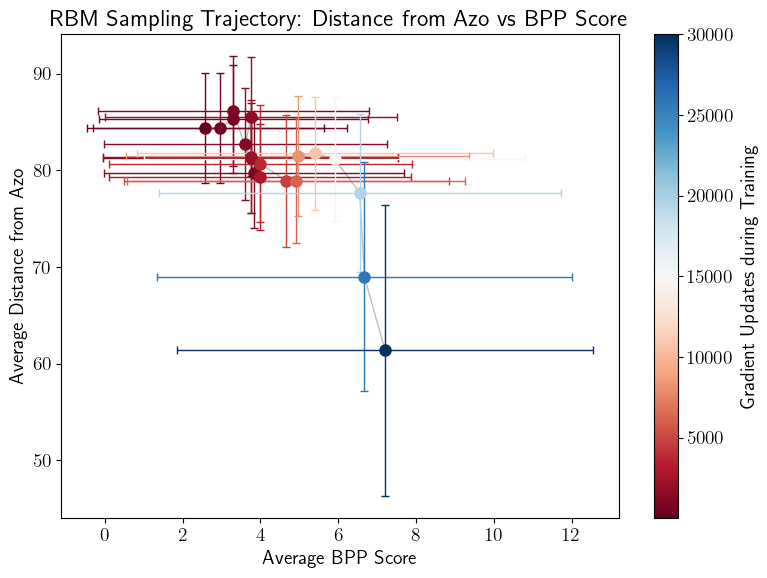

In [78]:
# Plot the bpp vs distance trajectory during RBM sampling with error bars
fig, ax = plt.subplots(figsize=(8,6))

# Create a colormap based on ptt_updates
norm = plt.Normalize(vmin=min(saved_updates), vmax=max(saved_updates))
colors = plt.cm.RdBu(norm(saved_updates))

# Plot line connecting all points (swapped x and y)
ax.plot(avg_bpp_scores_rbm, avg_distances_rbm, '-', color='gray', alpha=0.5, linewidth=1, zorder=1)

# Plot each point with error bars and individual colors (swapped x and y, xerr and yerr)
for i, (x, y, xerr, yerr) in enumerate(zip(avg_bpp_scores_rbm, avg_distances_rbm, std_bpp_scores_rbm, std_distances_rbm)):
    ax.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='o', color=colors[i], 
                markersize=8, capsize=3, elinewidth=1, markeredgewidth=1, zorder=2)

# Add colorbar
sm = plt.cm.ScalarMappable(cmap='RdBu', norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=ax, label='Gradient Updates during Training')

ax.set_xlabel('Average BPP Score')
ax.set_ylabel('Average Distance from Azo')
ax.set_title('RBM Sampling Trajectory: Distance from Azo vs BPP Score')
plt.tight_layout()